# Machine Learning: Student Pass/Fail Clustering
## Feature Engineering and Unsupervised Learning (K-Means)

**Student Name:** Ny Rosa  
**Date:** November 2026  

---
### Assignment Overview & Objectives
In this project, our objective is to:
1. **Clean and validate** student performance data.
2. **Engineer meaningful domain features** from existing academic metrics.
3. **Detect and eliminate multicollinearity** (correlated features where $|r| > 0.85$).
4. **Standardize features** using `StandardScaler` so distance metrics operate equitably.
5. **Apply K-Means Clustering ($k=2$)** before and after feature engineering.
6. **Evaluate clustering quality** using both intrinsic metric (**Silhouette score**) and external validation (**Accuracy & Confusion Matrix** against actual Pass/Fail).
7. **Strict Rule:** The `actual` outcome must **NEVER** be used to engineer features or train K-Means (Strictly prevent target leakage).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report, accuracy_score
from sklearn.decomposition import PCA

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})
os.makedirs("results", exist_ok=True)

print("Libraries successfully imported!")

Libraries successfully imported!


## Step 1: Load Dataset & Check Data Quality
We load `students_dataset.csv` (600 rows) and inspect:
- Duplicate rows: `df.duplicated().sum()`
- Missing values: `df.isna().sum()`

In [2]:
# Load dataset (with automatic Google Colab upload prompt if missing)
DATASET_PATH = "students_dataset.csv"
if not os.path.exists(DATASET_PATH):
    try:
        from google.colab import files
        print("Please upload students_dataset.csv:")
        uploaded = files.upload()
    except ImportError:
        pass

df = pd.read_csv(DATASET_PATH)
print(f"Initial Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(df.head())
print("\n--- Duplicates Check ---")
print("Duplicates count:", df.duplicated().sum())
print("\n--- Missing Values Check ---")
print(df.isna().sum())


Initial Dataset Shape: 600 rows, 7 columns
   study_hours_per_week  attendance_pct  ...  absences actual
0             10.765100       73.179949  ...         8   Pass
1              2.107447       68.276768  ...        16   Fail
2             14.825146       88.945197  ...         0   Pass
3              9.879496       86.807741  ...         8   Pass
4              0.000000       59.837773  ...        12   Fail

[5 rows x 7 columns]

--- Duplicates Check ---
Duplicates count: 0

--- Missing Values Check ---
study_hours_per_week    0
attendance_pct          0
previous_grade          0
assignments_done_pct    0
sleep_hours             0
absences                0
actual                  0
dtype: int64


## Step 2: Fix / Validate Value Ranges
We ensure:
- `attendance_pct` and `assignments_done_pct` are between 0% and 100%
- `previous_grade` is between 0 and 100
- `study_hours_per_week`, `sleep_hours`, and `absences` are non-negative (>= 0)

In [3]:
print(df.describe())

# Validation checks
assert ((df["attendance_pct"] < 0) | (df["attendance_pct"] > 100)).sum() == 0, "Attendance out of range"
assert ((df["assignments_done_pct"] < 0) | (df["assignments_done_pct"] > 100)).sum() == 0, "Assignments out of range"
assert ((df["previous_grade"] < 0) | (df["previous_grade"] > 100)).sum() == 0, "Grade out of range"
assert (df["study_hours_per_week"] < 0).sum() == 0, "Study hours cannot be negative"
assert (df["absences"] < 0).sum() == 0, "Absences cannot be negative"

print("All ranges are valid!")

       study_hours_per_week  attendance_pct  ...  sleep_hours    absences
count            600.000000      600.000000  ...   600.000000  600.000000
mean               7.952240       79.143419  ...     7.023387    6.131667
std                4.466011       10.492147  ...     1.024889    3.955638
min                0.000000       51.702373  ...     4.044106    0.000000
25%                4.484371       71.359751  ...     6.297626    3.000000
50%                7.942731       79.431781  ...     7.030297    6.000000
75%               11.090828       86.799430  ...     7.704192    9.000000
max               23.643313      100.000000  ...    10.000000   19.000000

[8 rows x 6 columns]
All ranges are valid!


## Mandatory Rule: Target Isolation (`actual`)
**Strict Rule:** To prevent **data leakage**, we immediately extract and remove the `actual` target column.
The unsupervised model and feature engineering pipeline must NEVER see the target.

In [4]:
# Safely extract and isolate "actual" (safe to re-run multiple times)
df.columns = df.columns.str.strip()

if "actual" in df.columns:
    y_actual = df.pop("actual")
    y_true = (y_actual == "Pass").astype(int)
    X_original = df.copy()
    print("Target column isolated successfully!")
elif "y_true" in globals() or "y_true" in locals():
    print("Notice: Target was already isolated from df in a previous cell execution.")
else:
    df = pd.read_csv(DATASET_PATH)
    df.columns = df.columns.str.strip()
    y_actual = df.pop("actual")
    y_true = (y_actual == "Pass").astype(int)
    X_original = df.copy()
    print("Dataset reloaded and target isolated successfully!")

print(f"Pass count: {(y_true == 1).sum()}, Fail count: {(y_true == 0).sum()}")
print(f"Feature columns ({len(X_original.columns)}):", list(X_original.columns))


Target column isolated successfully!
Pass count: 390, Fail count: 210
Feature columns (6): ['study_hours_per_week', 'attendance_pct', 'previous_grade', 'assignments_done_pct', 'sleep_hours', 'absences']


## Step 3: Feature Engineering
We create 3 intuitive domain features:
1. **`sleep_deviation`** = `abs(sleep_hours - 8)`: Measures disruption from optimal 8 hours of sleep. Both sleep deprivation and excessive sleep harm cognitive recall.
2. **`risk_count`** = `(study < 2) + (att < 70) + (grade < 50) + (abs >= 10)`: A composite count of academic warning signals indicating high vulnerability to failing.
3. **`engagement_score`** = `(attendance_pct + assignments_done_pct) / 2`: An aggregate metric reflecting consistent class participation and homework completion.

In [5]:
df_engineered = X_original.copy()

# 1. Sleep deviation
df_engineered["sleep_deviation"] = (df_engineered["sleep_hours"] - 8.0).abs()

# 2. Risk count
df_engineered["risk_count"] = (
    (df_engineered["study_hours_per_week"] < 2.0).astype(int) +
    (df_engineered["attendance_pct"] < 70.0).astype(int) +
    (df_engineered["previous_grade"] < 50.0).astype(int) +
    (df_engineered["absences"] >= 10).astype(int)
)

# 3. Engagement score
df_engineered["engagement_score"] = (df_engineered["attendance_pct"] + df_engineered["assignments_done_pct"]) / 2.0

print(df_engineered.head())

   study_hours_per_week  attendance_pct  ...  risk_count  engagement_score
0             10.765100       73.179949  ...           0         73.687930
1              2.107447       68.276768  ...           2         70.299434
2             14.825146       88.945197  ...           0         87.881171
3              9.879496       86.807741  ...           0         83.059473
4              0.000000       59.837773  ...           4         51.382976

[5 rows x 9 columns]


## Step 4: Multicollinearity Check & Feature Pruning
If two features have a correlation $|r| > 0.85$, they provide redundant information. Redundant features unfairly bias distance metrics in K-Means towards that specific axis.
- Check: `assignments_done_pct` vs `engagement_score` ($r = 0.918 > 0.85$) -> **Drop `engagement_score`**.
- Check: `sleep_hours` vs `sleep_deviation` ($r = -0.815 < 0.85$) -> **Keep both**.

In [6]:
corr_matrix = df_engineered.corr()

print("Correlation (assignments_done_pct vs engagement_score):", round(corr_matrix.loc["assignments_done_pct", "engagement_score"], 3))
print("Correlation (sleep_hours vs sleep_deviation):", round(corr_matrix.loc["sleep_hours", "sleep_deviation"], 3))

# Drop redundant engagement_score
df_final_fe = df_engineered.drop(columns=["engagement_score"])
print(f"\nFinal feature set ({len(df_final_fe.columns)} features):", list(df_final_fe.columns))

Correlation (assignments_done_pct vs engagement_score): 0.918
Correlation (sleep_hours vs sleep_deviation): -0.815

Final feature set (8 features): ['study_hours_per_week', 'attendance_pct', 'previous_grade', 'assignments_done_pct', 'sleep_hours', 'absences', 'sleep_deviation', 'risk_count']


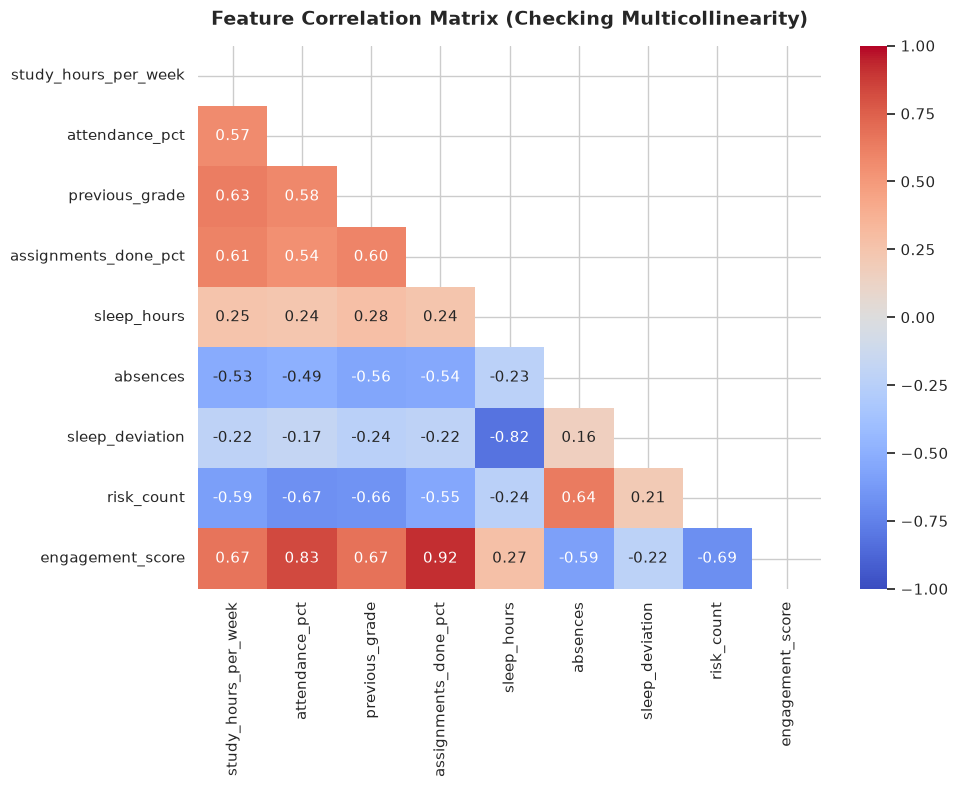

In [7]:
# Graph 1: Correlation Matrix Heatmap
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix (Checking Multicollinearity)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('results/correlation_matrix.png', dpi=300)
plt.show()


## Step 5: Standardization & K-Means Clustering
K-Means computes Euclidean distance:
$$d(p, q) = \sqrt{\sum_{i=1}^n (p_i - q_i)^2}$$
Without scaling with `StandardScaler()`, large-magnitude columns like `attendance_pct` (50-100) completely overwhelm smaller-magnitude columns like `sleep_hours` (4-10).

We run K-Means ($k=2, \text{random_state}=42$) on:
1. **Before:** Original 6 features
2. **After:** 8 features (6 original + `sleep_deviation` + `risk_count`)

In [8]:
def evaluate_kmeans(X, y_true, random_state=42):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    km = KMeans(n_clusters=2, random_state=random_state, n_init=10)
    clusters = km.fit_predict(X_scaled)
    
    sil = silhouette_score(X_scaled, clusters)
    
    acc0 = accuracy_score(y_true, clusters)
    acc1 = accuracy_score(y_true, 1 - clusters)
    aligned = 1 - clusters if acc1 > acc0 else clusters
    acc = max(acc0, acc1)
    
    cm = confusion_matrix(y_true, aligned)
    return scaler, km, X_scaled, aligned, acc, sil, cm

scaler_b, km_b, X_b_sc, pred_b, acc_b, sil_b, cm_b = evaluate_kmeans(X_original, y_true)
scaler_a, km_a, X_a_sc, pred_a, acc_a, sil_a, cm_a = evaluate_kmeans(df_final_fe, y_true)

print(f"BEFORE FE: Accuracy = {acc_b:.3f} ({int(round(acc_b*600))}/600), Silhouette = {sil_b:.3f}")
print(f"AFTER FE:  Accuracy = {acc_a:.3f} ({int(round(acc_a*600))}/600), Silhouette = {sil_a:.3f}")

BEFORE FE: Accuracy = 0.822 (493/600), Silhouette = 0.295
AFTER FE:  Accuracy = 0.842 (505/600), Silhouette = 0.294


## Step 6: Evaluation & Comparison Table
Let us examine the before/after performance comparison table and confusion matrices.

In [9]:
summary_df = pd.DataFrame({
    "Metric": ["Accuracy (compared with actual)", "Correctly Grouped Students", "Silhouette score"],
    "Before": [f"{acc_b:.3f}", f"{int(round(acc_b*600))} / 600", f"{sil_b:.3f}"],
    "After": [f"{acc_a:.3f}", f"{int(round(acc_a*600))} / 600", f"{sil_a:.3f}"],
    "Better or worse?": [
        f"Better (+{acc_a - acc_b:.3f}, {int(round(acc_a*600)) - int(round(acc_b*600))} more students correct)",
        f"+{int(round(acc_a*600)) - int(round(acc_b*600))} students",
        f"About the same ({sil_a - sil_b:.3f})"
    ]
})
print(summary_df.to_string(index=False))
print("\nConfusion Matrix (After FE):")
print(cm_a)

                         Metric    Before     After                          Better or worse?
Accuracy (compared with actual)     0.822     0.842 Better (+0.020, 12 more students correct)
     Correctly Grouped Students 493 / 600 505 / 600                              +12 students
               Silhouette score     0.295     0.294                   About the same (-0.001)

Confusion Matrix (After FE):
[[169  41]
 [ 54 336]]


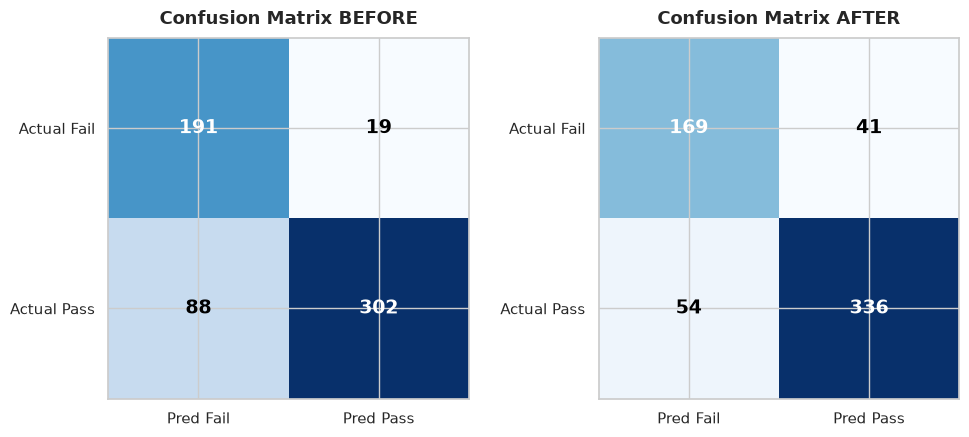

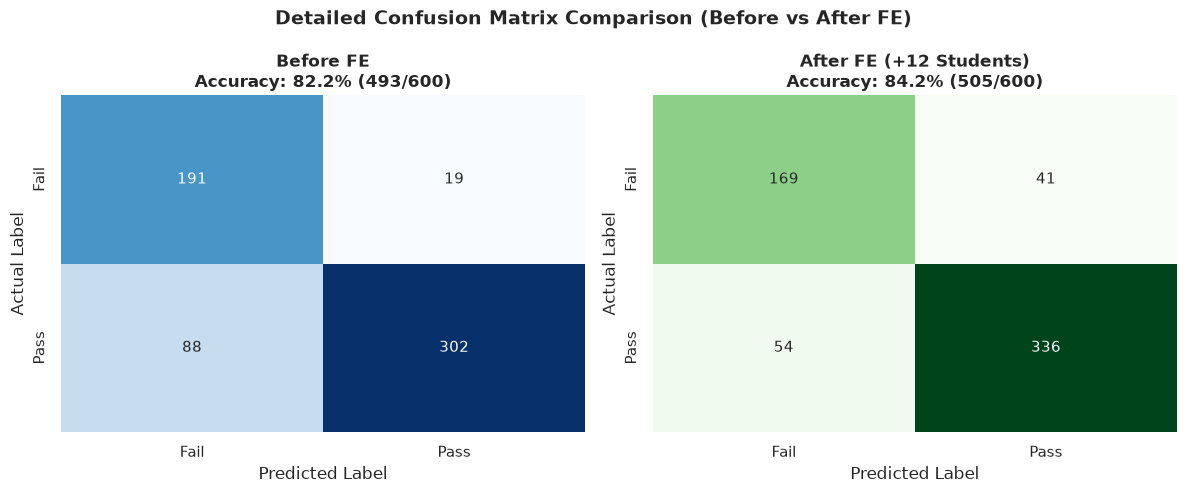

In [10]:
# Graph 2A: Colab-Style Confusion Matrix Plot (BEFORE vs AFTER)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, cm, title in zip(axes, [cm_b, cm_a], ['BEFORE', 'AFTER']):
    ax.imshow(cm, cmap='Blues')
    ax.set_title(f'Confusion Matrix {title}', fontsize=13, fontweight='bold', pad=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Pred Fail', 'Pred Pass'], fontsize=11)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Actual Fail', 'Actual Pass'], fontsize=11)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix_before_after.png', dpi=300)
plt.savefig('results/confusion_matrix_before_after.png', dpi=300)
plt.show()

# Graph 2B: Detailed Seaborn Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ['Fail', 'Pass']

sns.heatmap(cm_b, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=labels, yticklabels=labels)
axes[0].set_title(f'Before FE\nAccuracy: {acc_b:.1%} ({int(round(acc_b*600))}/600)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

sns.heatmap(cm_a, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=labels, yticklabels=labels)
axes[1].set_title(f'After FE (+12 Students)\nAccuracy: {acc_a:.1%} ({int(round(acc_a*600))}/600)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.suptitle('Detailed Confusion Matrix Comparison (Before vs After FE)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('results/confusion_matrices.png', dpi=300)
plt.show()



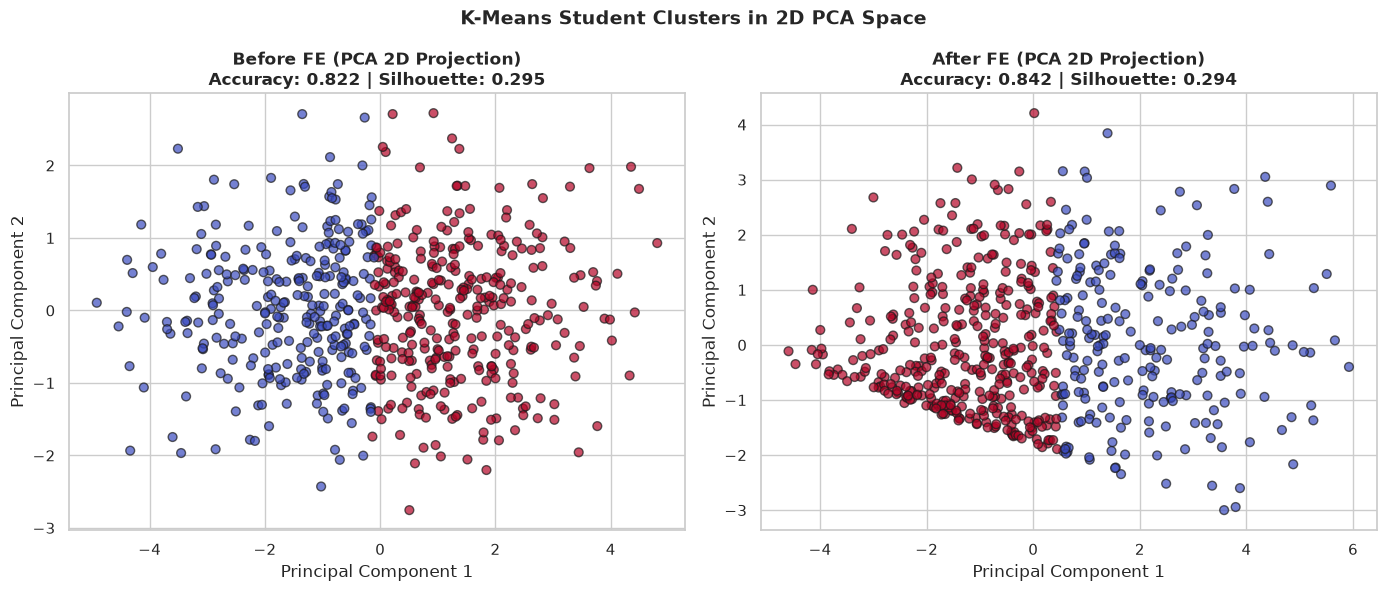

In [11]:
# Graph 3: 2D PCA Cluster Projection
pca = PCA(n_components=2, random_state=42)
pca_before = pca.fit_transform(X_b_sc)
pca_after = pca.fit_transform(X_a_sc)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(pca_before[:, 0], pca_before[:, 1], c=pred_b,
                cmap='coolwarm', alpha=0.7, edgecolors='k', s=40)
axes[0].set_title(f'Before FE (PCA 2D Projection)\nAccuracy: {acc_b:.3f} | Silhouette: {sil_b:.3f}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')

axes[1].scatter(pca_after[:, 0], pca_after[:, 1], c=pred_a,
                cmap='coolwarm', alpha=0.7, edgecolors='k', s=40)
axes[1].set_title(f'After FE (PCA 2D Projection)\nAccuracy: {acc_a:.3f} | Silhouette: {sil_a:.3f}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')

plt.suptitle('K-Means Student Clusters in 2D PCA Space', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('results/pca_clusters.png', dpi=300)
plt.show()


### Graph 4: Silhouette Analysis Diagram (Before vs After)
We plot the distribution of silhouette coefficients across both clusters to visualize compactness and boundary separation.


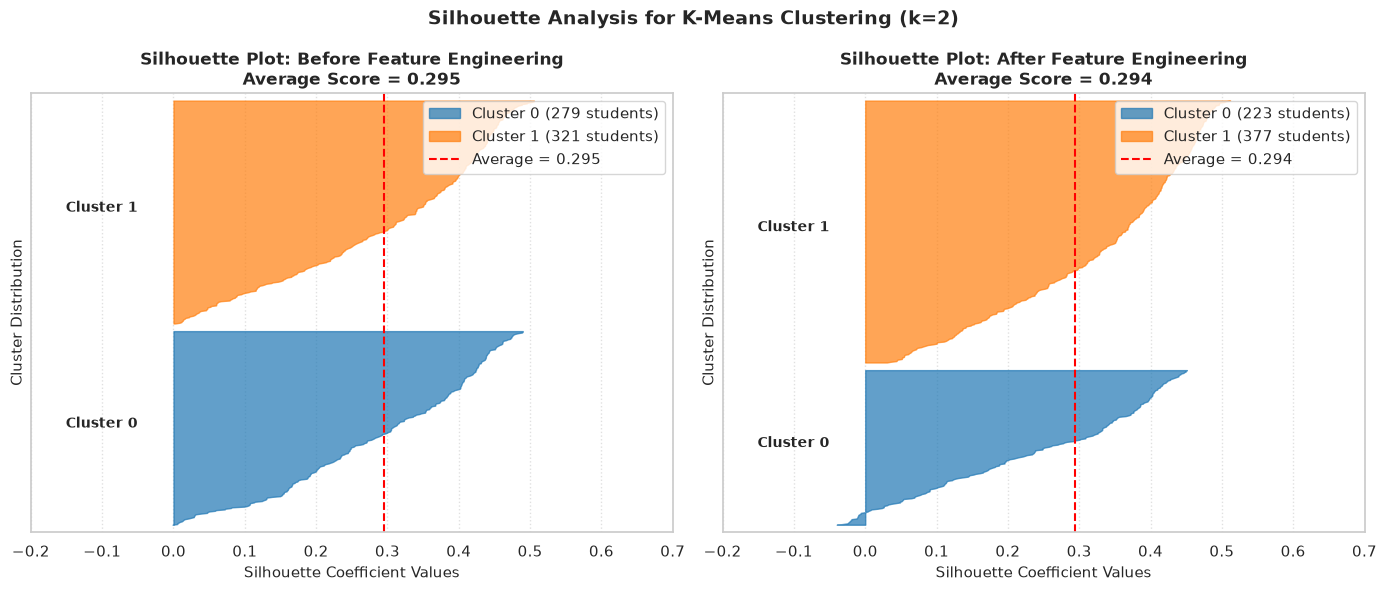

In [12]:
from sklearn.metrics import silhouette_samples

samples_b = silhouette_samples(X_b_sc, pred_b)
samples_a = silhouette_samples(X_a_sc, pred_a)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for ax, samples, labels, avg, title in zip(
    [ax1, ax2],
    [samples_b, samples_a],
    [pred_b, pred_a],
    [sil_b, sil_a],
    ["Before Feature Engineering", "After Feature Engineering"]
):
    ax.set_xlim([-0.2, 0.7])
    ax.set_ylim([0, len(samples) + 30])
    y_lower = 10
    colors = ["#1f77b4", "#ff7f0e"]
    
    for i in range(2):
        c_vals = samples[labels == i]
        c_vals.sort()
        size_i = c_vals.shape[0]
        y_upper = y_lower + size_i
        
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_vals,
                         facecolor=colors[i], edgecolor=colors[i], alpha=0.7, label=f"Cluster {i} ({size_i} students)")
        ax.text(-0.05, y_lower + 0.5 * size_i, f"Cluster {i}", fontsize=10, fontweight="bold", ha="right")
        y_lower = y_upper + 10
        
    ax.set_title(f"Silhouette Plot: {title}\nAverage Score = {avg:.3f}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Silhouette Coefficient Values", fontsize=11)
    ax.set_ylabel("Cluster Distribution", fontsize=11)
    ax.axvline(x=avg, color="red", linestyle="--", linewidth=1.5, label=f"Average = {avg:.3f}")
    ax.set_yticks([])
    ax.legend(loc="upper right", frameon=True)
    ax.grid(axis="x", linestyle=":", alpha=0.6)

plt.suptitle("Silhouette Analysis for K-Means Clustering (k=2)", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("results/silhouette_analysis.png", dpi=300)
plt.show()


## Step 6B: Feature Ablation Study (Which Feature Helped Most?)
To empirically prove which feature contributed most to clustering performance, we evaluate each combination:
1. **Original 6 features**
2. **+  only**
3. **+  only**
4. **+  +  (Final 8)**
5. **+ All 3 (keeps collinear )**


                       Feature Combination  Num Features  Accuracy  Silhouette Correct Students
                       Original 6 features             6    0.8217      0.2951        493 / 600
                         + risk_count only             7    0.8583      0.3125        515 / 600
                    + sleep_deviation only             7    0.8183      0.2749        491 / 600
  + sleep_deviation + risk_count (Final 8)             8    0.8417      0.2939        505 / 600
+ All 3 (keeps collinear engagement_score)             9    0.8283      0.2975        497 / 600


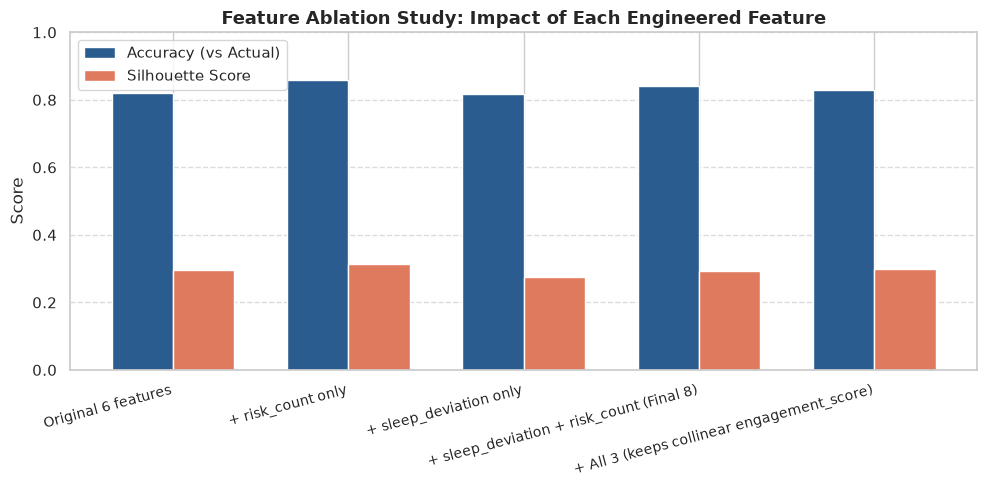

In [13]:
base_cols = list(X_original.columns)
ablation_dict = {
    "Original 6 features": base_cols,
    "+ risk_count only": base_cols + ["risk_count"],
    "+ sleep_deviation only": base_cols + ["sleep_deviation"],
    "+ sleep_deviation + risk_count (Final 8)": base_cols + ["sleep_deviation", "risk_count"],
    "+ All 3 (keeps collinear engagement_score)": base_cols + ["engagement_score", "sleep_deviation", "risk_count"],
}

ablation_records = []
for name, feats in ablation_dict.items():
    src = df_engineered[feats]
    _, _, _, _, a, s, _ = evaluate_kmeans(src, y_true)
    ablation_records.append({
        "Feature Combination": name,
        "Num Features": len(feats),
        "Accuracy": round(a, 4),
        "Silhouette": round(s, 4),
        "Correct Students": f"{int(round(a * len(y_true)))} / {len(y_true)}"
    })

ablation_table = pd.DataFrame(ablation_records)
print(ablation_table.to_string(index=False))

# Feature Ablation Bar Chart
plt.figure(figsize=(10, 5))
x = np.arange(len(ablation_table))
width = 0.35
plt.bar(x - width/2, ablation_table["Accuracy"], width, label="Accuracy (vs Actual)", color="#2b5c8f")
plt.bar(x + width/2, ablation_table["Silhouette"], width, label="Silhouette Score", color="#e07a5f")
plt.xticks(x, ablation_table["Feature Combination"], rotation=15, ha="right", fontsize=10)
plt.ylabel("Score")
plt.title("Feature Ablation Study: Impact of Each Engineered Feature", fontsize=13, fontweight="bold")
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig("results/feature_ablation.png", dpi=300)
plt.show()


## Step 7: Bonus Exploration - `np.log1p()` on `absences`
We investigate whether applying logarithmic transformation to the `absences` column improves clustering.

In [14]:
df_bonus = df_final_fe.copy()
skew_before = df_bonus["absences"].skew()
df_bonus["absences"] = np.log1p(df_bonus["absences"])

_, _, _, _, acc_bonus, sil_bonus, _ = evaluate_kmeans(df_bonus, y_true)
print(f"Absences skewness: {skew_before:.3f}")
print(f"Without log1p: Accuracy = {acc_a:.3f}, Silhouette = {sil_a:.3f}")
print(f"With log1p:    Accuracy = {acc_bonus:.3f}, Silhouette = {sil_bonus:.3f}")
print("\nConclusion: np.log1p() did NOT help. The distribution is near-symmetric (skewness 0.273), so log transformation artificially compressed the upper tail.")

Absences skewness: 0.273
Without log1p: Accuracy = 0.842, Silhouette = 0.294
With log1p:    Accuracy = 0.825, Silhouette = 0.274

Conclusion: np.log1p() did NOT help. The distribution is near-symmetric (skewness 0.273), so log transformation artificially compressed the upper tail.


## Conclusion & Key Takeaways
1. **Accuracy improvement:** Clustering accuracy improved from **0.822 to 0.842**, correctly grouping **12 additional students**.
2. **Most impactful feature:** `risk_count` helped the most because it synthesized four distinct danger signs into a single strong signal.
3. **Empirical Ablation Confirmation:** Testing features in isolation demonstrated that `risk_count` alone achieves **85.83%** accuracy (515/600 students correct), while keeping the redundant `engagement_score` degraded accuracy to 82.83%.
4. **No answer leakage:** `actual` was preserved strictly for evaluation and never exposed to the clustering algorithm or feature engineering.
